COCO subset of 5 classes, after removing:
- every image containing a crowd annotation (iscrowd=1)
- every image containing a person instance with less than 10 keypoints


## Step 1: Setup



In [1]:
from pathlib import Path
import json
import shutil
from collections import Counter, defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

coco_root = Path(r"C:\Users\shiif\Downloads\coco2017")
annotations_dir = coco_root / "annotations"

train_annotation_path = annotations_dir / "instances_train2017.json"
val_annotation_path = annotations_dir / "instances_val2017.json"

train_keypoints_path = annotations_dir / "person_keypoints_train2017.json"
val_keypoints_path = annotations_dir / "person_keypoints_val2017.json"

print("Train annotations path:", train_annotation_path)
print("Val annotations path:  ", val_annotation_path)
print("Train keypoints path:  ", train_keypoints_path)
print("Val keypoints path:    ", val_keypoints_path)


Train annotations path: C:\Users\shiif\Downloads\coco2017\annotations\instances_train2017.json
Val annotations path:   C:\Users\shiif\Downloads\coco2017\annotations\instances_val2017.json
Train keypoints path:   C:\Users\shiif\Downloads\coco2017\annotations\person_keypoints_train2017.json
Val keypoints path:     C:\Users\shiif\Downloads\coco2017\annotations\person_keypoints_val2017.json


In [2]:
def load_coco_annotations(json_path):
    with open(json_path, "r") as f:
        return json.load(f)


def compute_class_statistics(coco_data):
    category_id_to_name = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

    instance_counts = Counter()
    images_per_class = defaultdict(set)

    for ann in tqdm(coco_data["annotations"], desc="Processing annotations"):
        class_name = category_id_to_name[ann["category_id"]]
        instance_counts[class_name] += 1
        images_per_class[class_name].add(ann["image_id"])

    image_counts = {name: len(ids) for name, ids in images_per_class.items()}
    return instance_counts, image_counts


train_data = load_coco_annotations(train_annotation_path)
val_data = load_coco_annotations(val_annotation_path)

train_instance_counts_raw, train_image_counts_raw = compute_class_statistics(train_data)
val_instance_counts_raw, val_image_counts_raw = compute_class_statistics(val_data)

all_class_names = sorted(cat["name"] for cat in train_data["categories"])

coco_stats_raw_df = pd.DataFrame([
    {
        "Class": name,
        
        "Train Images": train_image_counts_raw.get(name, 0),
        "Train Instances": train_instance_counts_raw.get(name, 0),
        "Val Images": val_image_counts_raw.get(name, 0),
        "Val Instances": val_instance_counts_raw.get(name, 0),
    }
    for name in all_class_names
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

print("COCO class statistics (all classes, sorted by Train Instances):")
coco_stats_raw_df

Processing annotations: 100%|██████████| 36781/36781 [00:00<00:00, 1009889.34it/s]


COCO class statistics (all classes, sorted by Train Instances):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,64115,262465,2693,11004
1,car,12251,43867,535,1932
2,chair,12774,38491,580,1791
3,book,5332,24715,230,1161
4,bottle,8501,24342,379,1025
...,...,...,...,...,...
75,scissors,947,1481,28,36
76,bear,960,1294,49,71
77,parking meter,705,1285,37,60
78,toaster,217,225,8,9


## Step 2: Remove Crowd Images and High-Keypoint-Person Images

In [3]:
def remove_crowd_images(coco_data):
    crowd_image_ids = set(
        ann["image_id"] for ann in coco_data["annotations"] if ann.get("iscrowd", 0) == 1
    )

    original_image_count = len(coco_data["images"])
    original_annotation_count = len(coco_data["annotations"])

    filtered_images = [img for img in coco_data["images"] if img["id"] not in crowd_image_ids]
    filtered_annotations = [ann for ann in coco_data["annotations"] if ann["image_id"] not in crowd_image_ids]

    filtered_data = {
        "images": filtered_images,
        "annotations": filtered_annotations,
        "categories": coco_data["categories"],
    }

    counts = {
        "original_images": original_image_count,
        "original_annotations": original_annotation_count,
        "removed_images": len(crowd_image_ids),
        "images_left": len(filtered_images),
        "annotations_left": len(filtered_annotations),
    }

    return filtered_data, counts


train_data_no_crowd, train_crowd_counts = remove_crowd_images(train_data)
val_data_no_crowd, val_crowd_counts = remove_crowd_images(val_data)

print("Train split — after removing iscrowd=1 images:")
print(f"  Images before: {train_crowd_counts['original_images']:,}")
print(f"  Images removed (iscrowd=1): {train_crowd_counts['removed_images']:,}")
print(f"  Images left: {train_crowd_counts['images_left']:,}")
print(f"  Annotations before: {train_crowd_counts['original_annotations']:,}")
print(f"  Annotations left: {train_crowd_counts['annotations_left']:,}")

print("\nVal split — after removing iscrowd=1 images:")
print(f"  Images before: {val_crowd_counts['original_images']:,}")
print(f"  Images removed (iscrowd=1): {val_crowd_counts['removed_images']:,}")
print(f"  Images left: {val_crowd_counts['images_left']:,}")
print(f"  Annotations before: {val_crowd_counts['original_annotations']:,}")
print(f"  Annotations left: {val_crowd_counts['annotations_left']:,}")

Train split — after removing iscrowd=1 images:
  Images before: 118,287
  Images removed (iscrowd=1): 9,115
  Images left: 109,172
  Annotations before: 860,001
  Annotations left: 654,212

Val split — after removing iscrowd=1 images:
  Images before: 5,000
  Images removed (iscrowd=1): 411
  Images left: 4,589
  Annotations before: 36,781
  Annotations left: 27,436


In [10]:
# ============================================================
# BUILD KEYPOINT LOOKUP
# ============================================================

def build_keypoints_lookup(keypoints_json_path):
    """
    Build a lookup:
        annotation ID -> number of keypoints

    The COCO person keypoints JSON is read using ijson
    without loading the entire JSON file into memory.
    """

    import ijson

    keypoints_lookup = {}

    with open(keypoints_json_path, "rb") as f:
        for ann in ijson.items(f, "annotations.item"):
            keypoints_lookup[ann["id"]] = ann.get("num_keypoints", 0)

    return keypoints_lookup


# ============================================================
# LOAD TRAIN AND VAL KEYPOINT ANNOTATIONS
# ============================================================

train_keypoints_lookup = build_keypoints_lookup(
    train_keypoints_path
)

val_keypoints_lookup = build_keypoints_lookup(
    val_keypoints_path
)

print(
    "Train keypoint annotations loaded:",
    len(train_keypoints_lookup)
)

print(
    "Validation keypoint annotations loaded:",
    len(val_keypoints_lookup)
)


# ============================================================
# KEYPOINT THRESHOLD
# ============================================================

KEYPOINT_THRESHOLD = 10


# ============================================================
# REMOVE IMAGES WITH LOW-KEYPOINT PERSONS
# ============================================================

def remove_low_keypoint_person_images(
    coco_data,
    keypoints_lookup,
    keypoint_threshold
):
    """
    Remove entire images containing a person
    (category_id = 1) with <= keypoint_threshold
    visible keypoints.

    Person category ID is fixed as 1 in this dataset.
    """

    # Person is always category ID 1 in COCO
    person_category_id = 1

    # --------------------------------------------------------
    # Find image IDs containing low-keypoint persons
    # --------------------------------------------------------

    low_keypoint_image_ids = set(
        ann["image_id"]
        for ann in coco_data["annotations"]
        if ann["category_id"] == person_category_id
        and ann["id"] in keypoints_lookup
        and keypoints_lookup[ann["id"]] <= keypoint_threshold
    )

    # --------------------------------------------------------
    # Original counts
    # --------------------------------------------------------

    original_image_count = len(coco_data["images"])
    original_annotation_count = len(coco_data["annotations"])

    # --------------------------------------------------------
    # Remove those images
    # --------------------------------------------------------

    filtered_images = [
        img
        for img in coco_data["images"]
        if img["id"] not in low_keypoint_image_ids
    ]

    # --------------------------------------------------------
    # Remove ALL annotations belonging to removed images
    # --------------------------------------------------------

    filtered_annotations = [
        ann
        for ann in coco_data["annotations"]
        if ann["image_id"] not in low_keypoint_image_ids
    ]

    # --------------------------------------------------------
    # Create cleaned COCO dictionary
    # --------------------------------------------------------

    filtered_data = {
        "images": filtered_images,
        "annotations": filtered_annotations,
        "categories": coco_data["categories"],
    }

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    counts = {
        "original_images": original_image_count,
        "original_annotations": original_annotation_count,
        "removed_images": len(low_keypoint_image_ids),
        "images_left": len(filtered_images),
        "annotations_left": len(filtered_annotations),
    }

    return filtered_data, counts


# ============================================================
# APPLY TO TRAIN
# ============================================================

train_data_clean, train_kp_counts = remove_low_keypoint_person_images(
    train_data_no_crowd,
    train_keypoints_lookup,
    KEYPOINT_THRESHOLD
)


# ============================================================
# APPLY TO VALIDATION
# ============================================================

val_data_clean, val_kp_counts = remove_low_keypoint_person_images(
    val_data_no_crowd,
    val_keypoints_lookup,
    KEYPOINT_THRESHOLD
)


# ============================================================
# PRINT TRAIN RESULTS
# ============================================================

print(
    f"\nTrain split — after removing images with "
    f"<= {KEYPOINT_THRESHOLD} keypoints:"
)

print(
    f"  Images before (after crowd removal): "
    f"{train_kp_counts['original_images']:,}"
)

print(
    f"  Images removed (low-keypoint person): "
    f"{train_kp_counts['removed_images']:,}"
)

print(
    f"  Images left: "
    f"{train_kp_counts['images_left']:,}"
)

print(
    f"  Annotations before: "
    f"{train_kp_counts['original_annotations']:,}"
)

print(
    f"  Annotations left: "
    f"{train_kp_counts['annotations_left']:,}"
)


# ============================================================
# PRINT VALIDATION RESULTS
# ============================================================

print(
    f"\nVal split — after removing images with "
    f"<= {KEYPOINT_THRESHOLD} keypoints:"
)

print(
    f"  Images before (after crowd removal): "
    f"{val_kp_counts['original_images']:,}"
)

print(
    f"  Images removed (low-keypoint person): "
    f"{val_kp_counts['removed_images']:,}"
)

print(
    f"  Images left: "
    f"{val_kp_counts['images_left']:,}"
)

print(
    f"  Annotations before: "
    f"{val_kp_counts['original_annotations']:,}"
)

print(
    f"  Annotations left: "
    f"{val_kp_counts['annotations_left']:,}"
)

Train keypoint annotations loaded: 262465
Validation keypoint annotations loaded: 11004

Train split — after removing images with <= 10 keypoints:
  Images before (after crowd removal): 109,172
  Images removed (low-keypoint person): 37,218
  Images left: 71,954
  Annotations before: 654,212
  Annotations left: 309,433

Val split — after removing images with <= 10 keypoints:
  Images before (after crowd removal): 4,589
  Images removed (low-keypoint person): 1,556
  Images left: 3,033
  Annotations before: 27,436
  Annotations left: 13,180


In [11]:
import pickle
from pathlib import Path

cache_path = Path("train_data_clean.pkl")

with open(cache_path, "wb") as f:
    pickle.dump(train_data_clean, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved to {cache_path.resolve()} ({cache_path.stat().st_size / 1e6:.1f} MB)")

Saved to C:\Users\shiif\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\A4D7B6F15FACA74150C58F37BB47C9B35F66E86F\transfers\2026-41\train_data_clean.pkl (190.2 MB)


## Step 3: Classify Every Instance by Size (all 80 classes)

Uses the cleaned train data from Step 2 (`train_data_clean`) and the same thresholds / 640x640 letterbox scaling as `build_medium_large_dataset.py`.

In [12]:
MODEL_INPUT_SIZE = 640
SIZE_MODE = "letterbox"          # "letterbox" or "stretch" (same options as build_medium_large_dataset.py)

SIZE_THRESHOLDS_PX2 = [
    ("Very Small", 0, 16 ** 2),
    ("Small", 16 ** 2, 32 ** 2),
    ("Medium", 32 ** 2, 96 ** 2),
    ("Large", 96 ** 2, float("inf")),
]
SIZE_LABELS = [t[0] for t in SIZE_THRESHOLDS_PX2]


def classify_size(area_px2):
    for label, lo, hi in SIZE_THRESHOLDS_PX2:
        if lo <= area_px2 < hi:
            return label
    return SIZE_LABELS[-1]


def polygon_area(segmentation):
    """Fallback shoelace area, used only if COCO `area` is missing."""
    total = 0.0
    for poly in segmentation:
        pts = list(zip(poly[0::2], poly[1::2]))
        s = 0.0
        for i in range(len(pts)):
            x1, y1 = pts[i]
            x2, y2 = pts[(i + 1) % len(pts)]
            s += x1 * y2 - x2 * y1
        total += abs(s) / 2.0
    return total


def area_scale_factor(w, h, target, mode):
    """Area multiplier from original image resolution to the model input resolution."""
    if mode == "stretch":
        return (target / w) * (target / h)
    r = min(target / w, target / h)
    return r * r


category_id_to_name = {cat["id"]: cat["name"] for cat in train_data_clean["categories"]}
image_wh = {img["id"]: (img["width"], img["height"]) for img in train_data_clean["images"]}

class_size_counts = {name: Counter() for name in category_id_to_name.values()}
ann_size_label = {}   # annotation id -> size label (reused by the extraction cell)

for ann in tqdm(train_data_clean["annotations"], desc="Classifying instances by size"):
    if ann.get("iscrowd", 0):
        continue
    w, h = image_wh[ann["image_id"]]
    area = ann.get("area")
    if area is None:
        seg = ann.get("segmentation")
        area = polygon_area(seg) if isinstance(seg, list) else 0.0
    label = classify_size(area * area_scale_factor(w, h, MODEL_INPUT_SIZE, SIZE_MODE))
    ann_size_label[ann["id"]] = label
    class_size_counts[category_id_to_name[ann["category_id"]]][label] += 1

size_counts_df = pd.DataFrame([
    {"Class": name, **{label: counts[label] for label in SIZE_LABELS}, "Total": sum(counts.values())}
    for name, counts in class_size_counts.items()
]).sort_values("Total", ascending=False).reset_index(drop=True)

print(f"Classes: {len(size_counts_df)} | instances classified: {len(ann_size_label):,}")
print("\nOverall instances per size category:")
print(size_counts_df[SIZE_LABELS + ["Total"]].sum().to_string())

size_counts_df


Classifying instances by size: 100%|██████████| 309433/309433 [00:00<00:00, 320149.13it/s]

Classes: 80 | instances classified: 309,433

Overall instances per size category:
Very Small     32772
Small          49304
Medium        109631
Large         117726
Total         309433


,Class,Very Small,Small,Medium,Large,Total
0,person,0,0,8730,20265,28995
1,car,4396,4426,4746,1964,15532
2,chair,487,1889,7055,3941,13372
3,book,3207,4105,3494,1015,11821
4,bottle,2328,4247,4175,1021,11771
...,...,...,...,...,...,...
75,scissors,93,164,323,261,841
76,baseball bat,94,300,370,31,795
77,parking meter,144,132,185,318,779
78,toaster,4,33,116,36,189


## Step 4: Rank Classes by Medium + Large Instances

In [13]:
ranking_df = size_counts_df.copy()
ranking_df["Medium + Large"] = ranking_df["Medium"] + ranking_df["Large"]
ranking_df["% Medium + Large"] = (100 * ranking_df["Medium + Large"] / ranking_df["Total"]).round(2)

ranking_df = (
    ranking_df.sort_values("Medium + Large", ascending=False)
    .reset_index(drop=True)
)
ranking_df.index = ranking_df.index + 1
ranking_df.index.name = "Rank"

ranking_df[["Class", "Medium", "Large", "Medium + Large", "Total", "% Medium + Large"]]


,Class,Medium,Large,Medium + Large,Total,% Medium + Large
Rank,,,,,,
1,person,8730,20265,28995,28995,100.00
2,chair,7055,3941,10996,13372,82.23
3,dining table,1242,6064,7306,7684,95.08
4,car,4746,1964,6710,15532,43.20
5,bowl,2923,3209,6132,8560,71.64
...,...,...,...,...,...,...
76,sports ball,391,63,454,2525,17.98
77,toothbrush,259,150,409,1226,33.36
78,baseball bat,370,31,401,795,50.44


## Step 5: Extract Images with at least 1 Medium/Large Instance (+ label files)

Images and labels are **copied** (originals untouched). Each selected image keeps **all** of its instances in the label file (including Very Small / Small ones), so nothing becomes unlabeled background. YOLO class ids follow the sorted COCO category ids (0-79).

In [14]:
import shutil
from pathlib import Path

TOP_N = 5
KEEP_CATEGORIES = {"Medium", "Large"}
EXCLUDE_PERSON = False   # True -> skip "person" when picking the top classes

# --- top classes from the ranking
ranked = ranking_df["Class"].tolist()
if EXCLUDE_PERSON:
    ranked = [c for c in ranked if c != "person"]
top_classes = ranked[:TOP_N]

name_to_cat_id = {n: cid for cid, n in category_id_to_name.items()}
cat_id_to_yolo = {name_to_cat_id[n]: i for i, n in enumerate(top_classes)}   # YOLO ids 0..4 in rank order

print("Top classes (YOLO id -> class):")
for i, n in enumerate(top_classes):
    print(f"  {i}: {n}")

# --- output folders
medium_large_root = Path("datasets") / "coco_top5_medium_large_subset"
src_images_dir = coco_root / "train2017"
out_images_dir = medium_large_root / "images" / "train"
out_labels_dir = medium_large_root / "labels" / "train"

if out_images_dir.is_dir() and any(out_images_dir.iterdir()):
    raise SystemExit(f"Refusing to write into non-empty folder: {out_images_dir}\n"
                     f"Pick a new medium_large_root or empty it yourself.")
out_images_dir.mkdir(parents=True, exist_ok=True)
out_labels_dir.mkdir(parents=True, exist_ok=True)


def coco_bbox_to_yolo(bbox, image_width, image_height):
    x_min, y_min, box_width, box_height = bbox
    x_center = (x_min + box_width / 2) / image_width
    y_center = (y_min + box_height / 2) / image_height
    return x_center, y_center, box_width / image_width, box_height / image_height


# --- only keep annotations of the top classes
anns_by_image = defaultdict(list)
for ann in train_data_clean["annotations"]:
    if not ann.get("iscrowd", 0) and ann["category_id"] in cat_id_to_yolo:
        anns_by_image[ann["image_id"]].append(ann)

image_file_name = {img["id"]: img["file_name"] for img in train_data_clean["images"]}

# --- image qualifies if >=1 Medium/Large instance of a top class
selected_image_ids = [
    image_id for image_id, anns in anns_by_image.items()
    if any(ann_size_label[a["id"]] in KEEP_CATEGORIES for a in anns)
]
print(f"\nImages with >=1 Medium/Large instance of a top-{TOP_N} class: "
      f"{len(selected_image_ids):,} / {len(anns_by_image):,}")

# --- copy images + write labels
missing_images = []
written = defaultdict(Counter)   # class name -> size label -> count
for image_id in tqdm(selected_image_ids, desc="Copying images + labels"):
    file_name = image_file_name[image_id]
    src_path = src_images_dir / file_name
    if not src_path.is_file():
        missing_images.append(file_name)
        continue

    shutil.copy2(src_path, out_images_dir / file_name)

    w, h = image_wh[image_id]
    lines = []
    for ann in anns_by_image[image_id]:
        x_c, y_c, bw, bh = coco_bbox_to_yolo(ann["bbox"], w, h)
        lines.append(f"{cat_id_to_yolo[ann['category_id']]} {x_c:.6f} {y_c:.6f} {bw:.6f} {bh:.6f}")
        written[category_id_to_name[ann["category_id"]]][ann_size_label[ann["id"]]] += 1

    (out_labels_dir / (Path(file_name).stem + ".txt")).write_text("\n".join(lines))

n_img = len(list(out_images_dir.glob("*.jpg")))
n_lbl = len(list(out_labels_dir.glob("*.txt")))
print(f"\nCopied {n_img:,} images and {n_lbl:,} label files to: {medium_large_root.resolve()}")

summary_df = pd.DataFrame(
    [{"Class": n, **{l: written[n][l] for l in SIZE_LABELS}, "Total": sum(written[n].values())}
     for n in top_classes]
)
print("\nInstances written to labels:")
display(summary_df)

if missing_images:
    print(f"WARNING: {len(missing_images)} source images not found in {src_images_dir} (skipped)")

Top classes (YOLO id -> class):
  0: person
  1: chair
  2: dining table
  3: car
  4: bowl

Images with >=1 Medium/Large instance of a top-5 class: 32,174 / 33,651


Copying images + labels: 100%|██████████| 32174/32174 [02:45<00:00, 194.07it/s]



Copied 32,174 images and 32,174 label files to: C:\Users\shiif\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\A4D7B6F15FACA74150C58F37BB47C9B35F66E86F\transfers\2026-41\datasets\coco_top5_medium_large_subset

Instances written to labels:


,Class,Very Small,Small,Medium,Large,Total
0,person,0,0,8730,20265,28995
1,chair,381,1714,7055,3941,13091
2,dining table,84,269,1242,6064,7659
3,car,2521,3250,4746,1964,12481
4,bowl,503,1285,2923,3209,7920


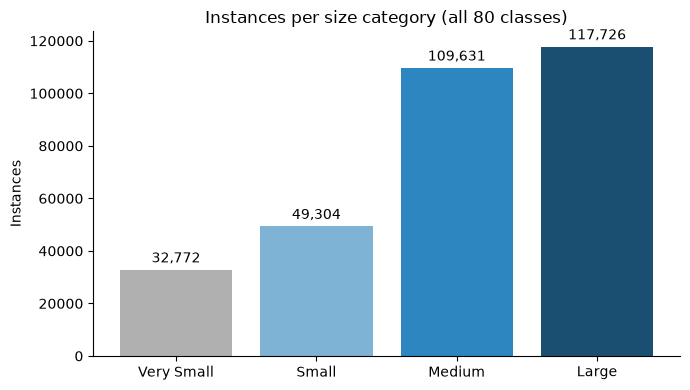

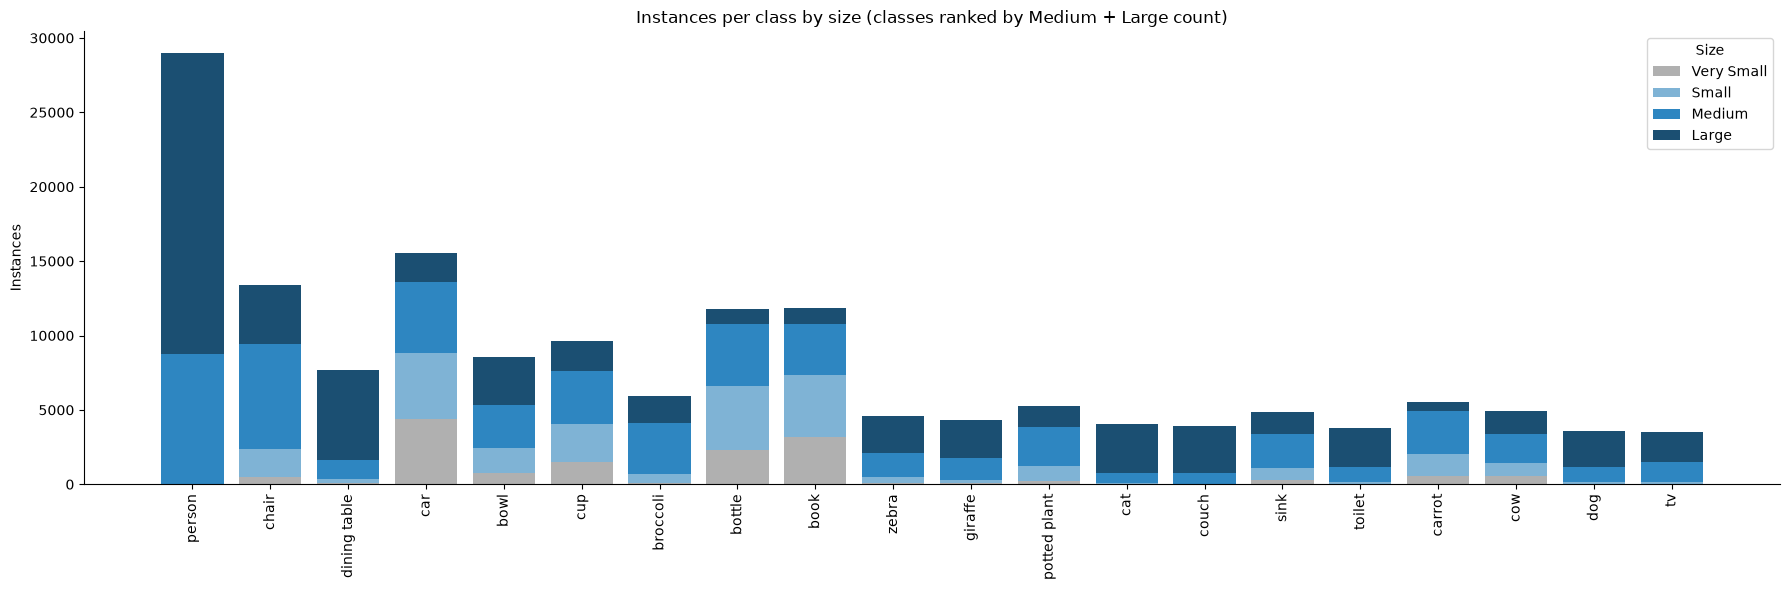

In [15]:
import matplotlib.pyplot as plt
import numpy as np

colors = {"Very Small": "#b0b0b0", "Small": "#7fb3d5", "Medium": "#2e86c1", "Large": "#1b4f72"}

# 1) Overall distribution across size categories
overall = size_counts_df[SIZE_LABELS].sum()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(overall.index, overall.values, color=[colors[l] for l in overall.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in overall.values], padding=3)
ax.set_title("Instances per size category (all 80 classes)")
ax.set_ylabel("Instances")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# 2) Per-class distribution, stacked by size, ordered by Medium + Large rank
plot_df = ranking_df.set_index("Class")[SIZE_LABELS].head(20)

fig, ax = plt.subplots(figsize=(18, 6))
x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))
for label in SIZE_LABELS:
    ax.bar(x, plot_df[label].values, bottom=bottom, label=label, color=colors[label])
    bottom += plot_df[label].values

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=90)
ax.set_ylabel("Instances")
ax.set_title("Instances per class by size (classes ranked by Medium + Large count)")
ax.legend(title="Size")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()